# SHAPformer: training, forecasting and explaining with dataframes

This notebook shows the dataframe interface of SHAPformer on the TransnetBW load data:

1. load the data and set up a SHAPformer model,
2. train the model (or load a trained one),
3. forecast the load of one week,
4. explain the forecast with Owen values,
5. create dependence plots from many explanations and compare the two explanation methods.

The switch `TRAINING` decides whether the model is trained from scratch and saved to `MODEL_PATH` (`True`), or whether the trained model is loaded from `MODEL_PATH` (`False`).

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import torch

import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

from src.models.shapformer import SHAPformer

TRAINING = True  # True: train the model from scratch and save it to MODEL_PATH; False: load the trained model from MODEL_PATH
MODEL_PATH = "model.ckpt"

## Load the data

The data has one row per hour (2015–2019), indexed by the local timestamp. It contains the target `load` (in MW) and the covariates:

- calendar features: `hour_of_day`, `day_of_week`, `month`, `holiday`,
- weather features: `temperature` (°C) and `precipitation`.

Categorical features must be integers starting at 0, so `month` is shifted from 1–12 to 0–11.

In [2]:
file = "./data/transnet/transnet_bw_hourly.csv"
df = pd.read_csv(file, parse_dates=[0], index_col=0)
df = df.drop(columns="irradiance")
df["month"] -= 1  # categorical features must start at 0
print(df)

                                load  hour_of_day  day_of_week  month  \
cet_cest_timestamp                                                      
2015-01-01 01:00:00+01:00  5279.7900            1            3      0   
2015-01-01 02:00:00+01:00  5024.5425            2            3      0   
2015-01-01 03:00:00+01:00  4879.9750            3            3      0   
2015-01-01 04:00:00+01:00  4858.5250            4            3      0   
2015-01-01 05:00:00+01:00  4600.1400            5            3      0   
...                              ...          ...          ...    ...   
2019-12-31 19:00:00+01:00  5914.4275           19            1     11   
2019-12-31 20:00:00+01:00  5620.2250           20            1     11   
2019-12-31 21:00:00+01:00  5517.5050           21            1     11   
2019-12-31 22:00:00+01:00  5487.2600           22            1     11   
2019-12-31 23:00:00+01:00  5293.9675           23            1     11   

                           holiday  temperature  p

## Create the model

A SHAPformer model is defined by its `target` column and the covariates in `feature_categories`: for each covariate, the number of categories, or `None` for a continuous feature. The covariates are known for the past and the future, the target only for the past.

Here, we use a small transformer with one layer, four attention heads and a hidden dimension of 128.

In [3]:
model = SHAPformer(
    target="load",
    feature_categories={
        "hour_of_day": 24,
        "day_of_week": 7,
        "month": 12,
        "holiday": 2,
        "temperature": None,
        "precipitation": None
    },
    d_model=128,
    n_layers=1,
    n_heads=4
)
print(model)

SHAPformer(
  (encoder_embedding): FeatureEmbedding(
    (embeddings): ParameterDict(
        (load): Object of type: LinearEmbedding
        (hour_of_day): Object of type: CategoricalEmbedding
        (day_of_week): Object of type: CategoricalEmbedding
        (month): Object of type: CategoricalEmbedding
        (holiday): Object of type: CategoricalEmbedding
        (temperature): Object of type: LinearEmbedding
        (precipitation): Object of type: LinearEmbedding
      (load): LinearEmbedding(
        (embedding): Linear(in_features=1, out_features=128, bias=True)
      )
      (hour_of_day): CategoricalEmbedding(
        (embedding): Embedding(24, 128)
      )
      (day_of_week): CategoricalEmbedding(
        (embedding): Embedding(7, 128)
      )
      (month): CategoricalEmbedding(
        (embedding): Embedding(12, 128)
      )
      (holiday): CategoricalEmbedding(
        (embedding): Embedding(2, 128)
      )
      (temperature): LinearEmbedding(
        (embedding): Li

## Train the model (or load a trained model)

`model.fit(df, VALIDATION_START)` uses all rows before `VALIDATION_START` for training and the rows from `VALIDATION_START` on for validation:

- A `StandardScaler` is fitted on the training part for each continuous variable (the target and the continuous covariates).
- Each sample is a week of past information (168 hours, including the target) and the following week of covariates; the model predicts the target for that following week.
- During training, every sample is masked with a random feature group subset, so the model learns to forecast with any subset of the feature groups. This is what makes the explanations below possible.
- After each epoch, the validation loss is computed. Training stops early when it has not improved for `patience` epochs, and the model with the lowest validation loss is restored.

With `TRAINING = True`, the trained model is saved to `MODEL_PATH`; with `TRAINING = False`, it is loaded from there.

In [4]:
DEVICE = "cuda"
VALIDATION_START = "2019-01-01"

if TRAINING:
    model.to(DEVICE)
    model = model.fit(df, VALIDATION_START, batch_size=128, patience=10)
    torch.save(model, MODEL_PATH)
else:
    model = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
    model.eval()

## Forecast one week

`model.predict(past, future)` takes two dataframes:

- `past`: the last 168 hours before the forecast, with the target and all covariates,
- `future`: the 168 hours to forecast, with the covariates only.

It returns the forecast in the unit of the target (MW), indexed by the timestamps of `future`. Here, we forecast the week starting on Monday, 15 April 2019, and compare it with the actual load.

<Axes: xlabel='cet_cest_timestamp'>

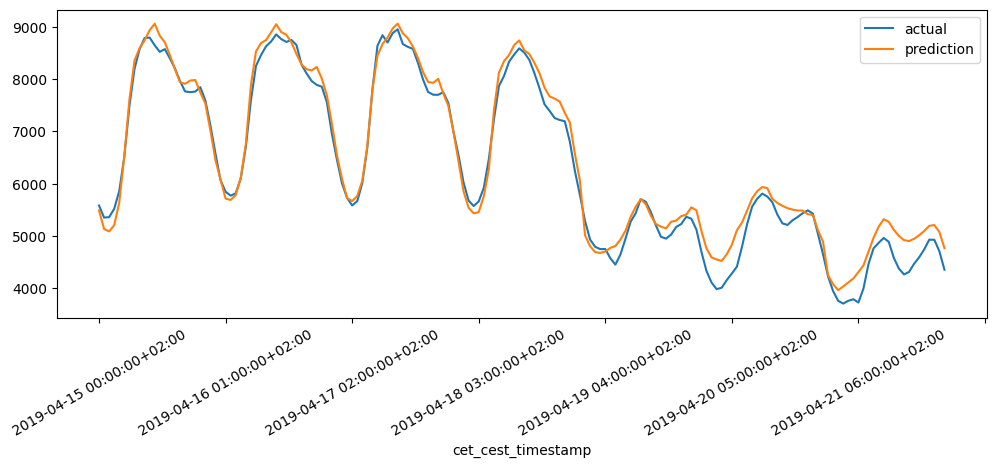

In [5]:
FORECAST_START = "2019-04-15 00:00:00+02:00"
INPUT_LENGTH = HORIZON = 168

start = df.index.get_loc(FORECAST_START)
past = df.iloc[start - INPUT_LENGTH:start]
future = df.iloc[start:start + HORIZON].drop(columns="load")

prediction = model.predict(past, future)

comparison = pd.DataFrame({"actual": df["load"].iloc[start:start + HORIZON], "prediction": prediction})
comparison.plot(figsize=(12, 4), rot=30)

## Explain the forecast

`model.explain(past, future)` takes the same inputs as `predict` and splits the forecast into contributions of feature groups: one group per covariate, and one group per day of the past load (`day 1` is the oldest day, `day 7` the most recent one). The explanation is a dictionary with

- `prediction`: the forecast with all feature groups,
- `base`: the forecast without any feature group,
- `shap_values`: one column per feature group, with its contribution for each forecasted hour,
- `past` and `future`: the inputs.

All values are in MW, and `base` + the sum of all `shap_values` = `prediction`. The values are Owen values: the past load days form one group, and the days are only attributed within that group.

> **Two explanation methods, selected with the `method` argument of `model.explain()`:**
>
> - **`method="exact"`** (default): evaluates the model with **all** feature group subsets (2<sup>13</sup> = 8192 for 6 covariates and 7 days) and computes the exact Owen values. The cost doubles with each additional feature group.
> - **`method="permutation"`**: **approximates** the Owen values by sampling `n_permutations` random orders of the feature groups (with the days kept together), with `seed` for reproducibility. Each permutation needs only 27 model evaluations, so it is much faster, but the values are only estimates: their error decreases with more permutations.

In [6]:
import matplotlib.pyplot as plt

explanation = model.explain(past, future)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 64/64 [00:01<00:00, 39.02it/s]


The explanation is plotted as a stacked area chart around the base value (dotted): positive contributions are stacked above the base, negative ones below it, so the forecast (solid line) lies between the upper and the lower edge of the stack. The dashed line is the actual load.

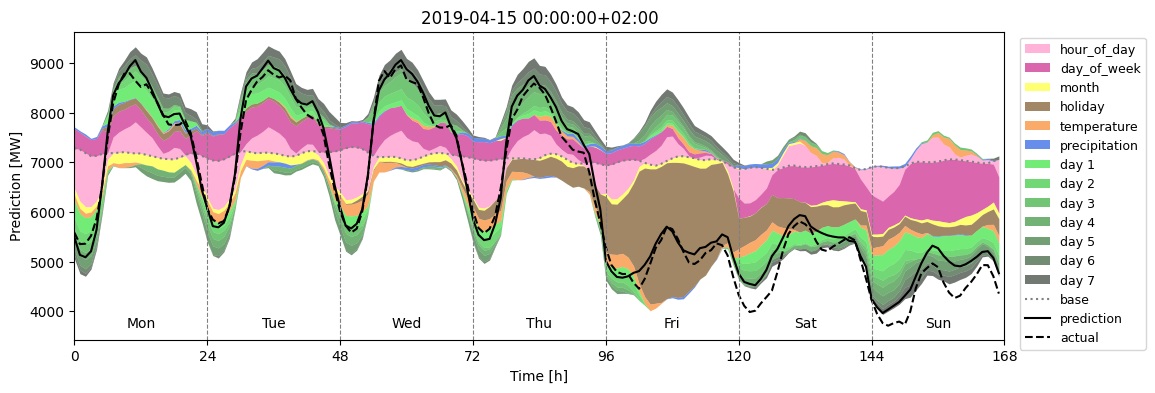

In [7]:
from src.plot import plot_explanation

actual = df["load"].iloc[start:start + HORIZON]
plot_explanation(explanation, actual=actual, title=f"{FORECAST_START}")
plt.show()

## Dependence plots of many explanations

A dependence plot shows, for one feature, how its value relates to its contribution: each dot is one explained forecast, with the feature value on the x-axis and its SHAP value at the forecasted hour `DEPENDENCE_HORIZON` (here the 24th hour) on the y-axis. For the load, the x-axis is the load one week before that hour, and the y-axis the sum of the contributions of all seven past days. For categorical features, the red line shows the mean contribution per category.

To compare the two explanation methods, we draw 1000 random forecast starts in the validation period (at any hour) and

1. explain the first 100 of them with `method="exact"`,
2. explain the **same** 100 forecasts with `method="permutation"`,
3. explain all 1000 forecasts with `method="permutation"`, reusing the 100 permutation explanations from step 2.

For each run, the average runtime per explanation is measured. The next cell defines the forecast starts and the helper functions `explain_starts` (explains the given forecast starts and measures the runtime) and `plot_dependences` (dependence plots of all features).

In [8]:
import math
import random
import time
from src.plot import plot_dependence

SEED = 42
N_PERMUTATIONS = 10  # permutations per explanation for method="permutation"
DEPENDENCE_HORIZON = 24  # plot the SHAP values of the 24th predicted hour; None plots all 168 hours
N_COLUMNS = 4

# 1000 random forecast starts in the validation period (same split as in fit), at any hour, in random order;
# the first 100 of them are explained with both methods, so their dependence plots can be compared
timestamps = pd.to_datetime(df.index, utc=True)
first_validation_start = int((timestamps < pd.Timestamp(VALIDATION_START, tz="UTC")).sum())
starts_1000 = random.Random(SEED).sample(range(first_validation_start, len(df) - HORIZON + 1), 1000)
starts_100 = starts_1000[:100]


def explain_starts(starts, method="exact", seed_offset=0, **explain_args):
    # explains the forecasts starting at the given positions and reports the average runtime per explanation;
    # with method="permutation", each explanation gets its own seed (SEED + seed_offset + its index)
    start_time = time.perf_counter()
    explanations = []
    for i, s in enumerate(starts):
        if method == "permutation":
            explain_args["seed"] = SEED + seed_offset + i
        explanations.append(
            model.explain(df.iloc[s - INPUT_LENGTH:s], df.iloc[s:s + HORIZON].drop(columns="load"), method=method,
                          **explain_args)
        )
    runtime = (time.perf_counter() - start_time) / len(starts)
    print(f"{len(starts)} explanations, method {method}: {runtime:.3f} s per explanation on average")
    return explanations, runtime


def plot_dependences(explanations, title):
    n_rows = math.ceil(len(model.feature_names) / N_COLUMNS)
    fig, axs = plt.subplots(n_rows, N_COLUMNS, figsize=(6 * N_COLUMNS, 4.5 * n_rows))
    for ax, feature in zip(axs.flat, model.feature_names):
        plot_dependence(explanations, feature, horizon=DEPENDENCE_HORIZON, ax=ax)
    for ax in axs.flat[len(model.feature_names):]:
        ax.set_visible(False)
    fig.suptitle(title, fontsize=16)
    fig.tight_layout()
    plt.show()


runtimes = {}

### 100 explanations with `method="exact"`

The exact Owen values of 100 forecasts. These serve as the reference for the permutation method.

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 64/64 [00:01<00:00, 38.34it/s]


100 explanations, method exact: 1.877 s per explanation on average


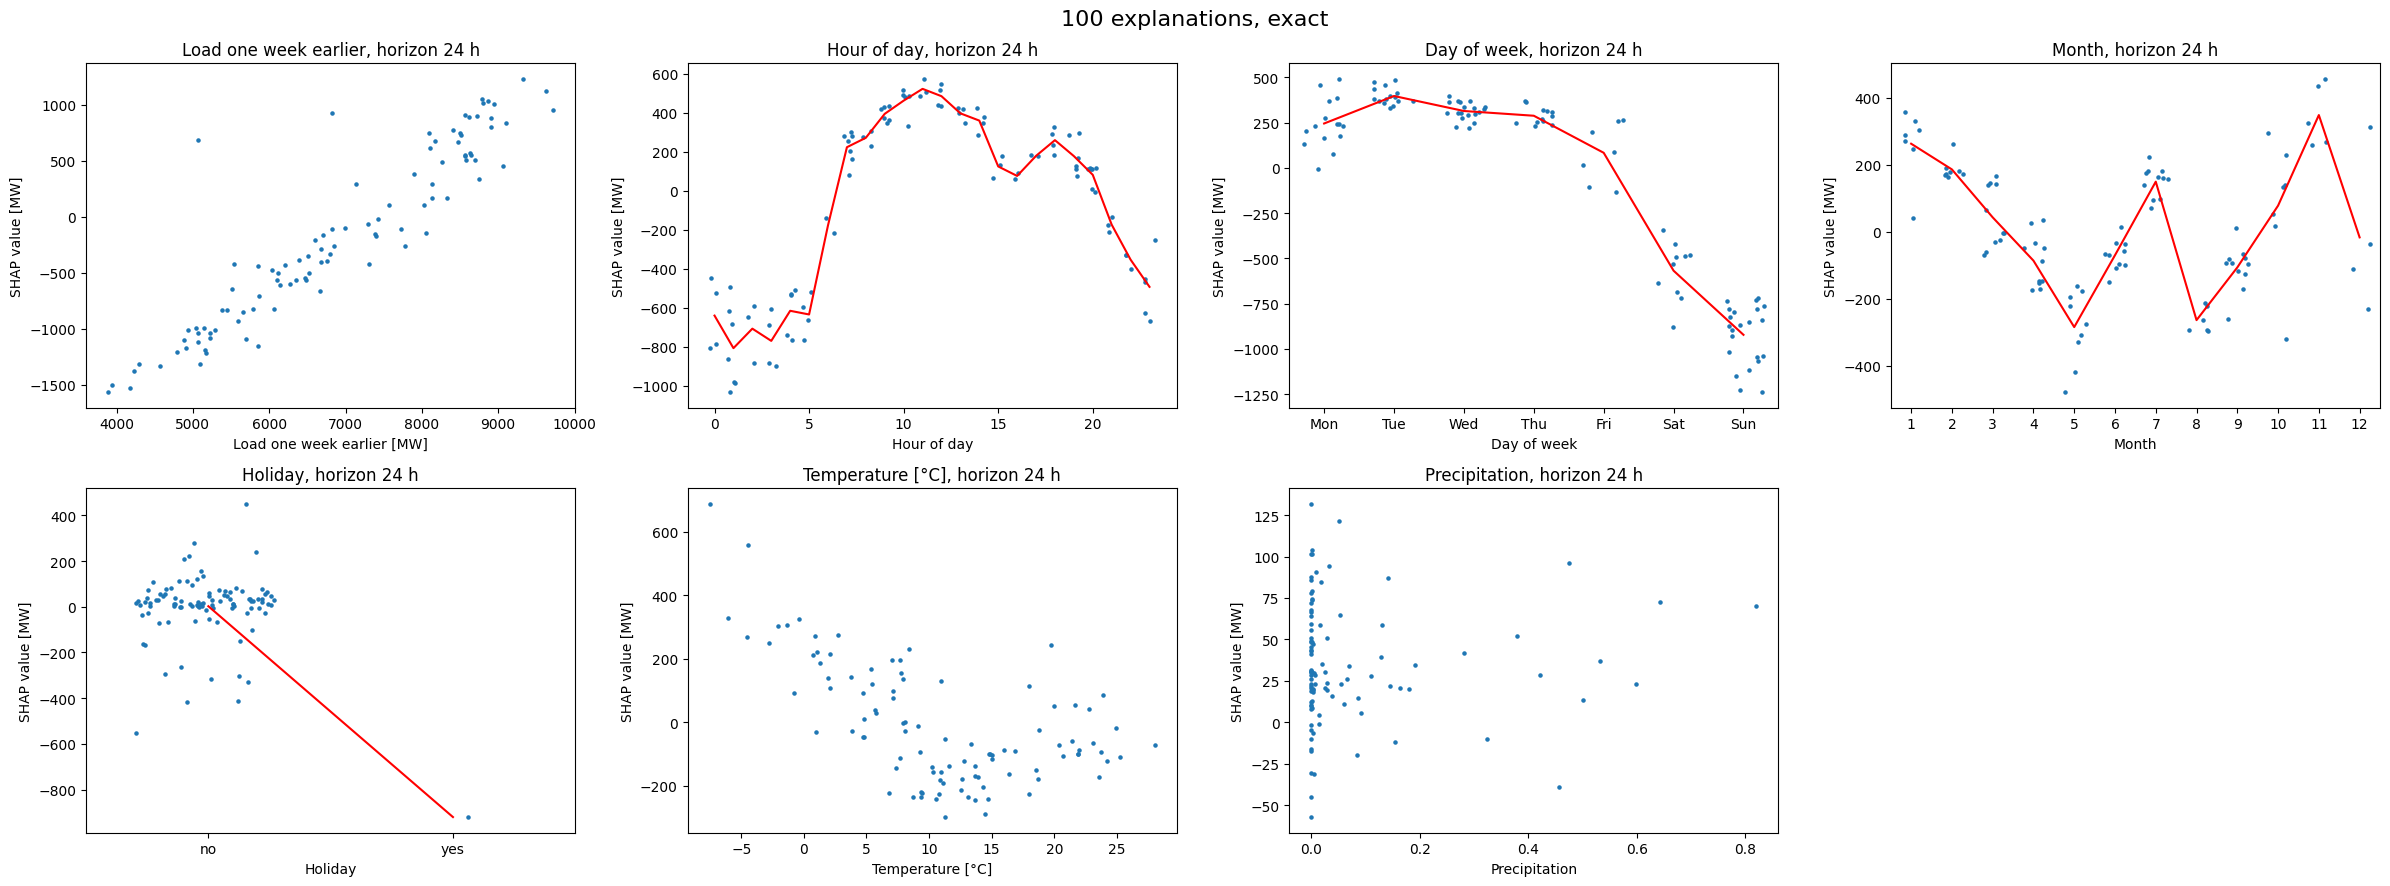

In [9]:
explanations_exact_100, runtimes["100 x exact"] = explain_starts(starts_100, method="exact")
plot_dependences(explanations_exact_100, "100 explanations, exact")

### The same 100 explanations with `method="permutation"`

The same 100 forecasts, explained with `N_PERMUTATIONS` sampled permutations each (each explanation with its own seed). Since the forecasts are the same, differences to the plots above come only from the approximation: the overall patterns should match, while the dots scatter more.

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:00<00:00, 210.84it/s]


100 explanations, method permutation: 0.071 s per explanation on average


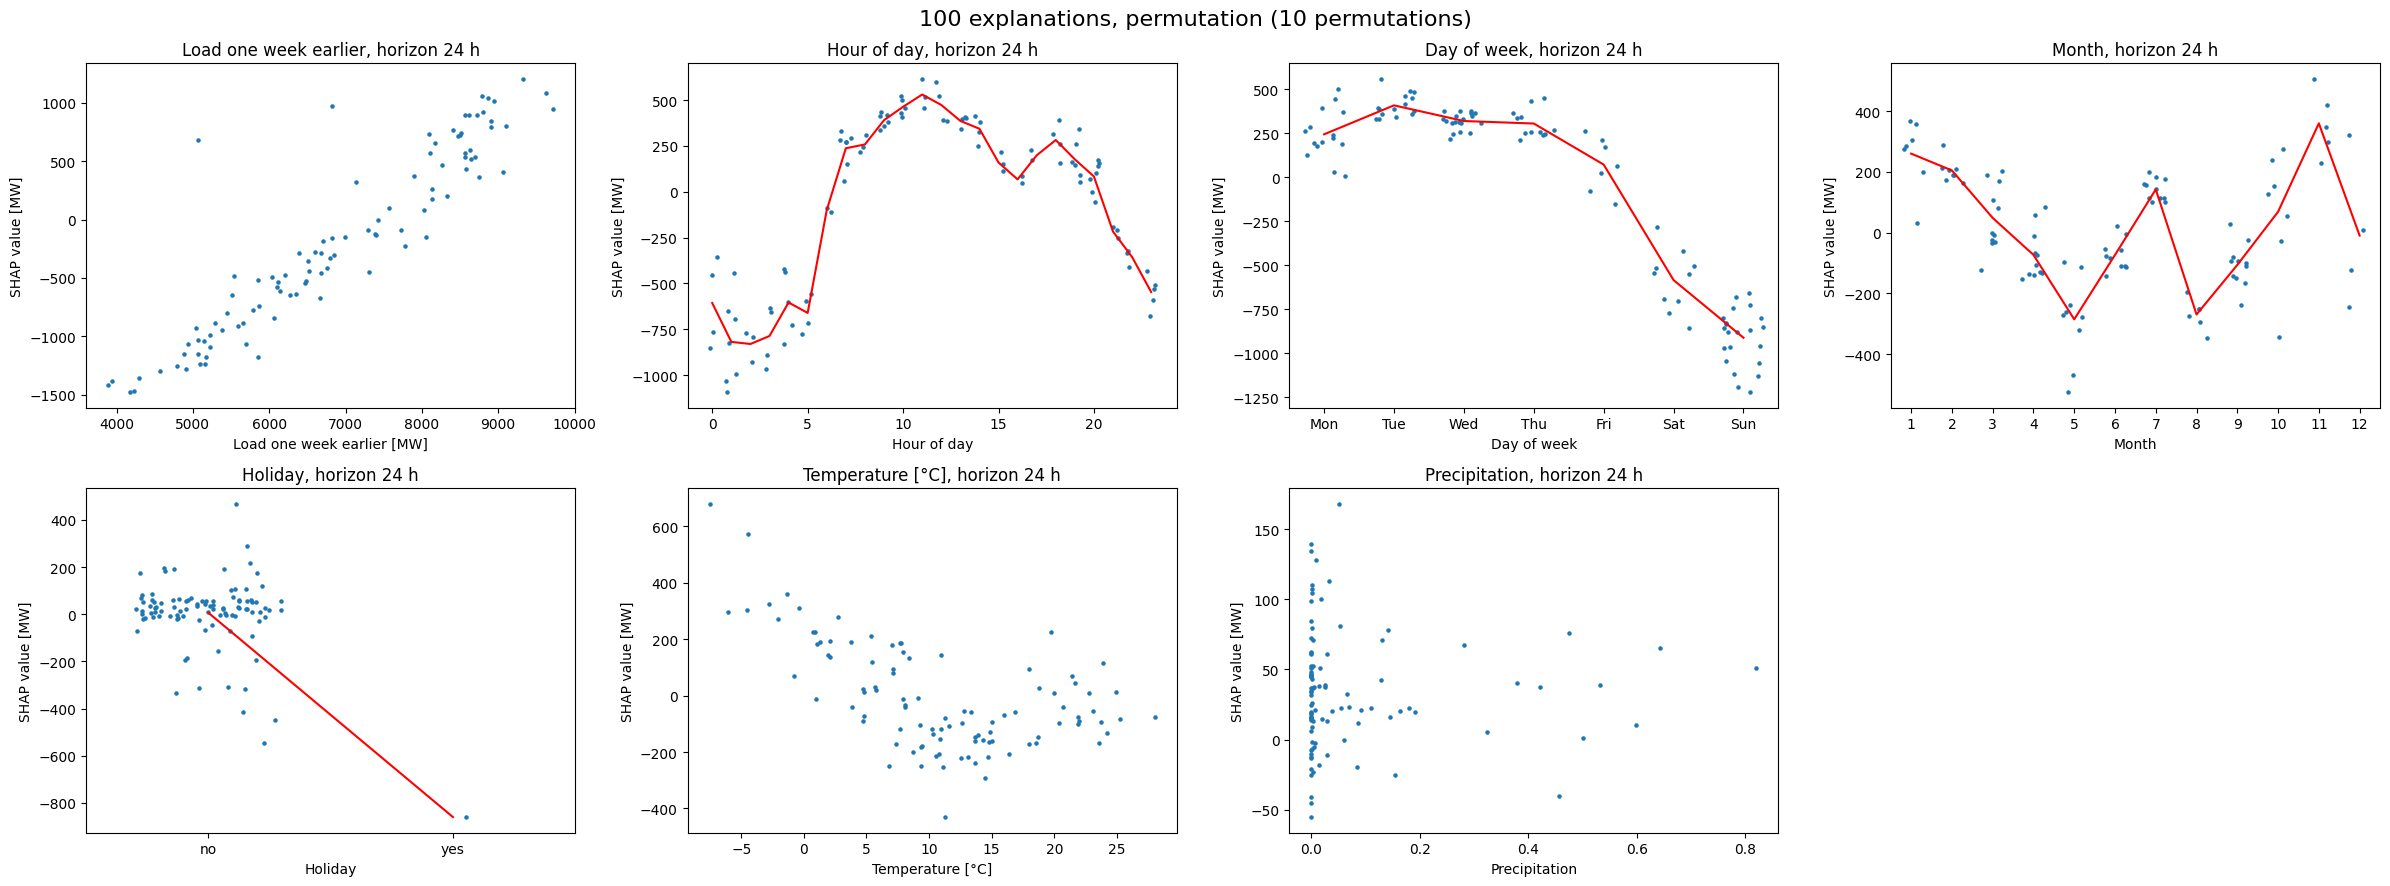

In [10]:
# same 100 forecast starts as with the exact method
explanations_permutation_100, runtimes[f"100 x permutation ({N_PERMUTATIONS} permutations)"] = explain_starts(
    starts_100, method="permutation", n_permutations=N_PERMUTATIONS
)
plot_dependences(explanations_permutation_100, f"100 explanations, permutation ({N_PERMUTATIONS} permutations)")

### 1000 explanations with `method="permutation"`

All 1000 forecasts: the 100 permutation explanations from above are reused, and the remaining 900 forecasts are explained. With more forecasts, rarer situations such as holidays become visible in the dependence plots.

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:00<00:00, 192.96it/s]


900 explanations, method permutation: 0.073 s per explanation on average


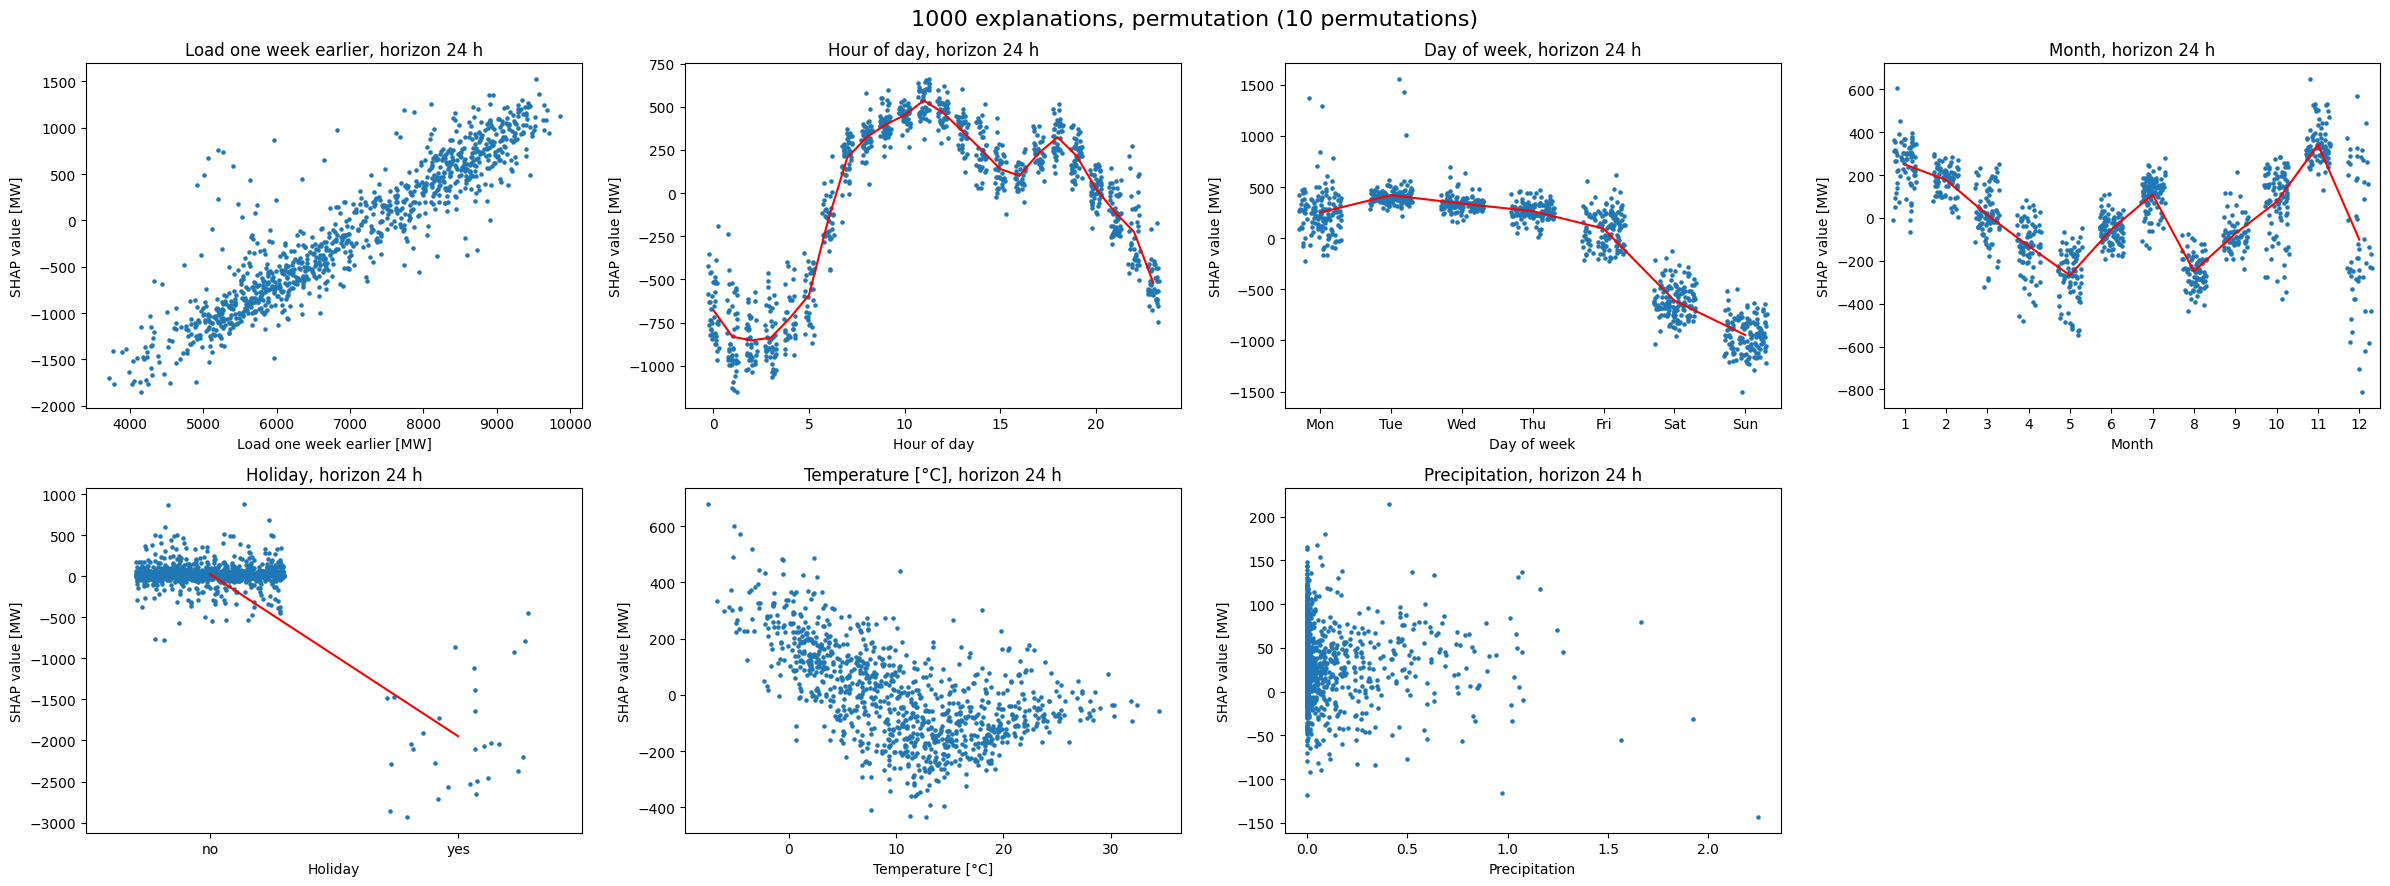

In [11]:
# reuses the 100 permutation explanations from above and explains the remaining 900 forecast starts
# (seed_offset=100 continues the seeds of the first 100 explanations)
explanations_permutation_900, runtimes[f"1000 x permutation ({N_PERMUTATIONS} permutations, 900 new)"] = explain_starts(
    starts_1000[100:], method="permutation", n_permutations=N_PERMUTATIONS, seed_offset=100
)
explanations_permutation_1000 = explanations_permutation_100 + explanations_permutation_900
plot_dependences(explanations_permutation_1000, f"1000 explanations, permutation ({N_PERMUTATIONS} permutations)")

### Runtime per explanation

The average runtime per explanation of each run. With 13 feature groups, an exact explanation took about 2 s and a permutation explanation with 10 permutations about 0.07 s on an RTX 3070 Laptop GPU. The permutation method pays off most with many feature groups, where the exact method becomes expensive.

In [12]:
pd.Series(runtimes, name="average runtime per explanation [s]").round(3).to_frame()

,average runtime per explanation [s]
100 x exact,1.877
100 x permutation (10 permutations),0.071
"1000 x permutation (10 permutations, 900 new)",0.073
